# Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Car data

In [ ]:
g = 9.81
# Car dimensions & weight
length = 3.999  # m
width = 1.775  # m
height = 1.597  # m
wheelbase = 2.57  # m
m_curb = 1195  # kg
m_driver = 75  # kg
m_tot = m_curb + m_driver
gamma = 1.04

# ROlling resistance properties
SCx = 2.38 * 0.29  # m^2, for standard version
rho_air = 1.23  # kg/m^3
R_e = 0.1778/2  # that is the radius of the tire, not effective radius
f_rr_0 = 0.008
f_rr_2 = 0.4e-7 * (3.6**2)  # from (kmh)^2 to (m/s)^2

# drivetrain properties
eta_t = 0.9875
i_tot = 9.665

# engine properties
P_max = 75e3  # W
T_max = 250  # Nm
omega_base = P_max/T_max  # rad/s

P_regen_max = 50e3  # W, max regen power

a1, a2, a3 = +8.079E-1, +1.827E-5,  6.760E-4
a4, a5, a6 = -1.087E-9, +2.434E-9, -1.864E-6

# Drivetrain efficiency map function

In [ ]:
import numpy as np


def efficiency_drivetrain(omega, T):
    """The efficiency of the drivetrain (transmission & electric motor using the Golverk formula)

    Parameters:
    - omega : angular velocity of motor [rad/s] (scalar or numpy array)
    - T : torque of motor [Nm] (scalar or numpy array)

    Returns:
    - eta: efficiency of the motor
    """
    # Check if inputs are arrays or sequences
    is_array = isinstance(omega, np.ndarray) or isinstance(T, np.ndarray)

    if not is_array:
        # Scalar logic (original behavior)
        if (omega <= omega_base and T > T_max) or (T * omega > P_max):
            return 0.05
        eta = a1 + a2 * T + a3 * omega + a4 * \
            (T ** 2) + a5 * T * omega + a6 * (omega ** 2)
        return eta * eta_t
    else:
        # Vectorized array logic
        omega = np.asarray(omega)
        T = np.asarray(T)

        eta = a1 + a2 * T + a3 * omega + a4 * \
            (T ** 2) + a5 * T * omega + a6 * (omega ** 2)
        eta = eta * eta_t

        # Use element-wise logical operators (& and |) and np.where
        invalid = ((omega <= omega_base) & (T > T_max)) | ((T * omega) > P_max)
        return np.where(invalid, 0.05, eta)

# Resistance Force function

In [ ]:
def F_res(v, theta):
    F_rr = f_rr_0 + f_rr_2 * v**2
    F_aero = 0.5 * rho_air * SCx * v**2
    F_slope = m_tot * g * np.sin(theta)

    return F_rr + F_aero + F_slope


def F_acc(m_curb, m_driver, gamma, dv_dt):
    return (gamma * m_curb + m_driver) * dv_dt

# Consumption at constant speed

Energy consumption at 30.0 km/h : 0.819 (kWh/100km)
Energy consumption at 50.0 km/h : 2.275 (kWh/100km)
Energy consumption at 90.0 km/h : 7.370 (kWh/100km)
Energy consumption at 120.0 km/h : 13.101 (kWh/100km)


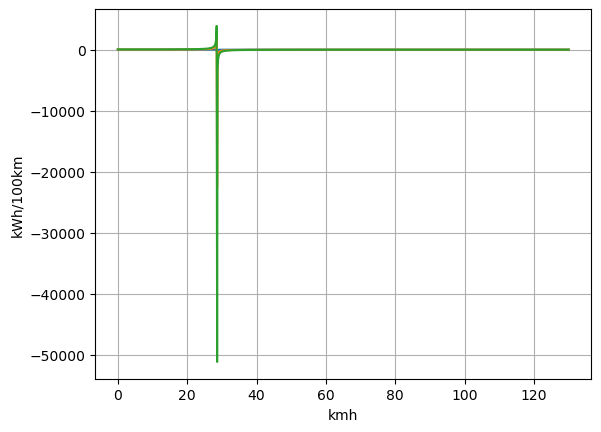

In [ ]:
v = np.array([30, 50, 90, 120]) / 3.6  # velocities to test, kmh to m/s


# Energy consumption per km = F * 1km (J/km) /(1000*3600) (=>kwh/km)
for i in range(len(v)):
    print(
        f"Energy consumption at {v[i] * 3.6:.1f} km/h : {F_res(v[i], 0) * 1000_00 / (1000*3600):.3f} (kWh/100km)")


v = np.linspace(0, 130, 1000)/3.6
slope_percent = np.array([0, 5, 10])  # they are there to draw multiple curves
slope_angle = np.arctan2(slope_percent, 100)  # = theta in the F_res fct
for i in range(len(slope_angle)):

    omega = (v / R_e) * i_tot
    torque = (F_res(v, slope_angle[i]) * R_e) / (i_tot * eta_t)

    F_mot = (F_res(v, slope_angle[i])) / \
        eta_t / efficiency_drivetrain(omega, torque)
    plt.plot(v*3.6, F_mot * 1000_00 / (1000*3600))

plt.xlabel("kmh")
plt.ylabel("kWh/100km")
plt.grid()
plt.show()

# WLTP analysis

total distance :  83744.60000000008
1801
1801
1.6412261827455875e-07 kWh/100km


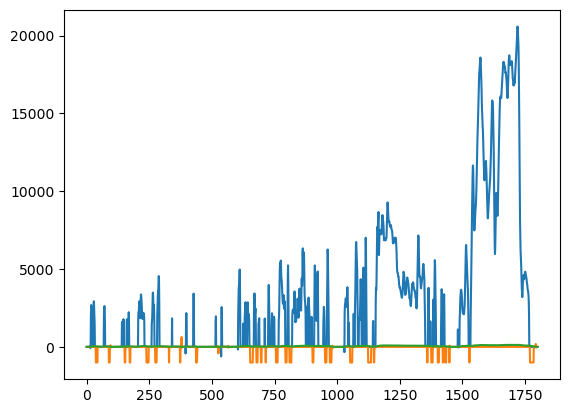

In [ ]:
df = pd.read_excel("WLTP.xlsx", skiprows=0, decimal=",")

phase = df['Phase'].to_numpy()[1:]  # string says which phase we are in
total_time = df['Total elapsed time'].to_numpy()[1:]  # [s]
phase_time = df['Phase elapsed time'].to_numpy()[1:]  # [s]
speed = df['WLTC class 3, version 5, vehicle speed'].to_numpy()[1:]  # [m/s]
dv_dt = np.gradient(speed, total_time)
delta_t = 1  # [s]
delta_x = speed * delta_t
E_tot = 0  # J, cumulative


def Power_regen(v, dv_dt):
    # net force available for regen
    F_regen = (F_acc(m_curb, m_driver, gamma, dv_dt) + F_res(v, 0))
    if F_regen >= 0:
        return 0.0
    else:
        omega = (v / R_e) * i_tot
        torque = abs((F_regen * R_e) / (i_tot * eta_t))
        eta = efficiency_drivetrain(omega, torque)
        P_regen = max(-50_000, F_regen * v) / eta
        return P_regen


def Power_consumption(v, dv_dt):
    # tractive force = force to counteract res. & accelerate
    F_trac = (F_acc(m_curb, m_driver, gamma, dv_dt) + F_res(v, 0))
    if F_trac <= 0:
        return 0.0
    else:
        omega = (v / R_e) * i_tot
        torque = (F_trac * R_e) / (i_tot * eta_t)
        P_trac = F_trac * v
        eta = efficiency_drivetrain(omega, torque)
        return P_trac / eta


p_cons_array = np.zeros(len(total_time))
p_regen_array = np.zeros(len(total_time))
total_distance = np.sum(speed * delta_t)
print("total distance : ", total_distance)
print(len(total_time))
print(len(speed))
for i in range(len(speed)):
    p_cons_array[i] = Power_consumption(float(speed[i]), float(dv_dt[i]))
    p_regen_array[i] = Power_regen(float(speed[i]), float(dv_dt[i]))
    E_tot += Power_consumption(speed[i], dv_dt[i]) * delta_t
    E_tot += Power_regen(speed[i], dv_dt[i]) * delta_t


E_tot_kWh = E_tot / (1000*3600)
WLTP_consumption = E_tot_kWh / total_distance / 100_000

print(WLTP_consumption, "kWh/100km")


plt.plot(total_time, p_cons_array/1000, label="P Cons")
plt.plot(total_time, p_regen_array/1000, label="P regen")
plt.plot(total_time, speed, label="speed")
plt.ylim(-1000, 1000)